# Reproduce Figure 2: mode numbers in a bend

This notebook uses a small extract from the full code associated with the paper
below, focused on Bessel cross products and radial modes in waveguide bends:

Martin Horvat and Tomaž Prosen (2007). **The bends on a quantum waveguide
and cross-products of Bessel functions.** *Journal of Physics A: Mathematical
and Theoretical*, **40**(24), 6349–6379.
[doi:10.1088/1751-8113/40/24/006](https://doi.org/10.1088/1751-8113/40/24/006).

It reproduces **Figure 2, p. 6354**, of that paper. Please cite the paper when
using these methods or reproducing its results.

Both panels use **$q=0.6$**, $a=1-q$, and the boundary equation
$$Z_{\nu,k}(q)=J_\nu(kq)Y_\nu(k)-Y_\nu(kq)J_\nu(k)=0.$$

- **(a)** $k$ versus signed order: $x=\nu$ on the real branch and
  $x=-\eta$ on the imaginary branch $\nu=i\eta$; limits $x\in[-100,100]$, $k\in[0,100]$.
- **(b)** $k^2$ versus $\lambda=\nu^2$; limits $\lambda\in[-10^4,10^4]$, $k^2\in[0,2\times10^4]$.

Solid curves are computed using the extracted C++ library; dashed curves are
**equation (26)**, $(ka)^2-(\nu\log q)^2\approx(\pi n)^2$.
This notebook reproduces Figure 2 only. It does not digitize the image.

The CSV and executed plots are included. Set `recompute=True` below to rebuild
and regenerate all branches (a few minutes).

License for this notebook and generated numerical data: GPL-3.0-or-later.

In [1]:
from pathlib import Path
import subprocess
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import mpmath as mp

root = Path.cwd().resolve()
if root.name == 'notebooks':
    root = root.parent
assert (root/'CMakeLists.txt').exists(), 'Start in standalone/ or standalone/notebooks/'
recompute = False
csv_path = root/'notebooks'/'paper_figure2.csv'
if recompute or not csv_path.exists():
    subprocess.run(['cmake', '-S', str(root), '-B', str(root/'build'),
                    '-DCMAKE_BUILD_TYPE=Release'], check=True, capture_output=True)
    subprocess.run(['cmake', '--build', str(root/'build'), '-j2'], check=True, capture_output=True)
    exe = root/'build'/('paper_figure2.exe' if os.name == 'nt' else 'paper_figure2')
    print(subprocess.check_output([str(exe), str(csv_path)], text=True).strip())
data = np.genfromtxt(csv_path, delimiter=',', names=True)
q = 0.6
a = 1-q
L = abs(np.log(q))
branches = int(data['n'].max())
assert len(data) == branches*601
assert np.all(np.isfinite(data['eigenvalue']))
print(f'{branches} branches; 601 sampled wavenumbers per branch; q={q:g}')

26 branches; 601 sampled wavenumbers per branch; q=0.6


Each branch has a fixed radial index $n$, ordered by decreasing $\lambda_n$.
The $k=0$ endpoint is known analytically: $\lambda_n=-(\pi n/|\log q|)^2$.
For $k>0$ all points are C++ cross-product roots. We add the exact zero-order
threshold of each visible branch, using high-precision $Z_{0,k}(q)=0$,
so the signed square-root axis is continuous as a mode changes from imaginary
to real. These added threshold points use mpmath independently of the C++ code.

In [2]:
mp.mp.dps = 50
thresholds = {}
q_mp = mp.mpf('0.6')
def zero_order_boundary(k):
    return mp.besselj(0,k*q_mp)*mp.bessely(0,k) - mp.bessely(0,k*q_mp)*mp.besselj(0,k)
for n in range(1, branches+1):
    estimate = mp.pi*n/(1-q_mp)
    crossing = mp.findroot(zero_order_boundary, (estimate-mp.mpf('0.2'), estimate+mp.mpf('0.2')))
    if crossing <= np.sqrt(20000):
        thresholds[n] = float(crossing)

curves = {}
for n in range(1, branches+1):
    d = data[data['n'] == n]
    k = d['k'].copy()
    lam = d['eigenvalue'].copy()
    assert np.all(np.diff(lam) > 0), f'Branch {n}: nonmonotone eigenvalue'
    if n in thresholds:
        k = np.append(k, thresholds[n])
        lam = np.append(lam, 0.0)
    ix = np.argsort(k)
    curves[n] = k[ix], lam[ix]
print(f'Added {len(thresholds)} zero-order crossings; first at k={thresholds[1]:.10f}')

Added 18 zero-order crossings; first at k=7.8284401472


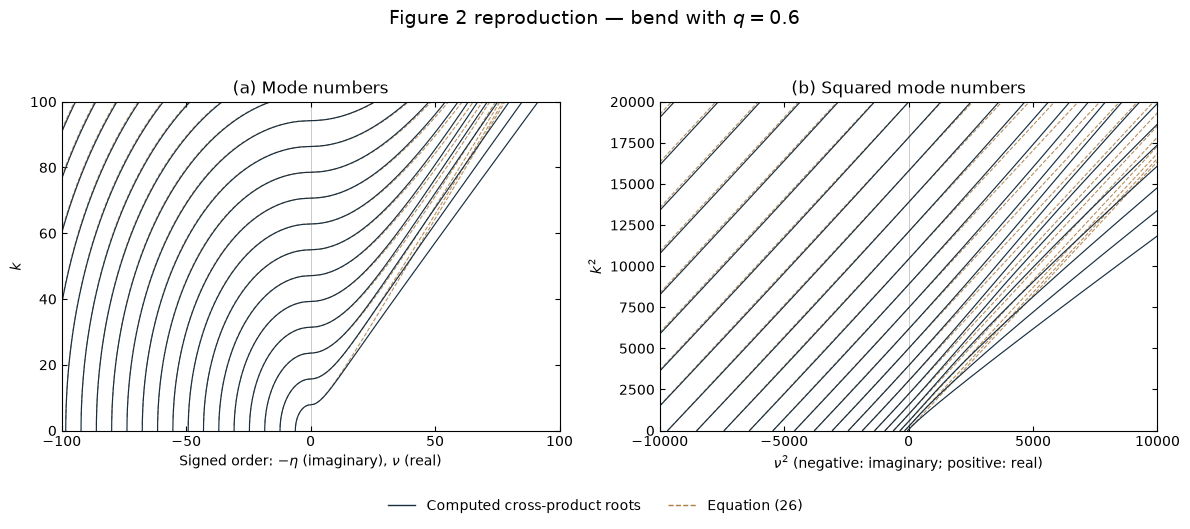

In [3]:
# Equation (26), expressed in the two coordinate systems of the paper.
def approx_k2_signed(x, n):
    return ((np.pi*n)**2 + np.sign(x)*x*x*L*L)/(a*a)
def approx_k2_lambda(lam, n):
    return ((np.pi*n)**2 + lam*L*L)/(a*a)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.3))
solid = '#172f42'
dashed = '#ac7d45'
x = np.linspace(-100, 100, 2201)
lam_grid = np.linspace(-10000, 10000, 2201)
for n in range(1, branches+1):
    # Approximation first; exact curves remain visible when close together.
    y2 = approx_k2_signed(x, n)
    mask = (y2 >= 0) & (y2 <= 10000)
    axes[0].plot(x[mask], np.sqrt(y2[mask]), '--', color=dashed, lw=.8, alpha=.85)
    y2 = approx_k2_lambda(lam_grid, n)
    mask = (y2 >= 0) & (y2 <= 20000)
    axes[1].plot(lam_grid[mask], y2[mask], '--', color=dashed, lw=.8, alpha=.85)
    k, lam = curves[n]
    signed = np.sign(lam)*np.sqrt(np.abs(lam))
    axes[0].plot(signed, k, color=solid, lw=.85)
    axes[1].plot(lam, k*k, color=solid, lw=.85)

axes[0].set(xlim=(-100,100), ylim=(0,100), xlabel=r'Signed order: $-\eta$ (imaginary), $\nu$ (real)', ylabel=r'$k$', title='(a) Mode numbers')
axes[1].set(xlim=(-10000,10000), ylim=(0,20000), xlabel=r'$\nu^2$ (negative: imaginary; positive: real)', ylabel=r'$k^2$', title='(b) Squared mode numbers')
axes[0].set_xticks([-100,-50,0,50,100])
axes[1].set_xticks([-10000,-5000,0,5000,10000])
for ax in axes:
    ax.tick_params(direction='in', top=True, right=True)
    ax.axvline(0, color='0.7', lw=.5, zorder=0)
fig.suptitle(r'Figure 2 reproduction — bend with $q=0.6$', fontsize=14)
fig.legend(handles=[Line2D([0],[0],color=solid,lw=1,label='Computed cross-product roots'),
                    Line2D([0],[0],color=dashed,lw=1,ls='--',label='Equation (26)')],
           loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(.5,.005))
fig.tight_layout(rect=(0,.08,1,.94))
fig.savefig(root/'notebooks'/'paper_figure2.png', dpi=180)
fig.savefig(root/'notebooks'/'paper_figure2.svg')
plt.show()

## Independent numerical checks

Selected real and imaginary orders from the CSV are checked against arbitrary-precision
Bessel functions, using enough precision for cancellation at imaginary orders.
The reference roots below are independently refined with mpmath. This is a sampled
check of the reproduction, not a uniform error bound or a certified root-count proof.

Equation (26) is an approximation: visible separation from the solid curves is
expected, especially near low-index turning points. No fit parameters are used.

In [4]:
checks = []
for requested_k, n in [(10,1), (10,5), (50,4), (50,10), (120,1), (120,20)]:
    branch = data[data['n'] == n]
    row = branch[np.argmin(abs(branch['k']-requested_k))]
    k = mp.mpf(str(row['k']))
    v = mp.mpf(str(row['order']))
    imaginary = bool(row['imaginary'])
    mp.mp.dps = max(80, int(2*mp.pi*v/mp.log(10))+60) if imaginary else 80
    # Reparse decimal CSV values at the reference precision.
    k = mp.mpf(str(row['k']))
    v = mp.mpf(str(row['order']))
    def f(t):
        order = 1j*t if imaginary else t
        return mp.re(mp.besselj(order,k*q_mp)*mp.bessely(order,k)
                     - mp.bessely(order,k*q_mp)*mp.besselj(order,k))
    reference = mp.findroot(f, (v-mp.mpf('.001'), v+mp.mpf('.001')))
    error = float(abs(v-reference))
    checks.append((float(k), n, 'imaginary' if imaginary else 'real', float(v), error))
    assert error < 2e-7, (float(k),n,error)
print(' k         n  kind        order          absolute order error')
for k,n,kind,v,error in checks:
    print(f'{k:8.4f} {n:3d}  {kind:9s} {v:12.7f}  {error:.3g}')
assert len(thresholds) == 18
print('All sampled reference roots passed.')

 k         n  kind        order          absolute order error
  9.8995   1  real         4.8028512  3.35e-12
  9.8995   5  imaginary   29.7375940  1.51e-11
 49.9689   4  real        29.7758622  1.36e-11
 49.9689  10  imaginary   47.2432578  2.54e-11
119.9725   1  real       110.8430743  1.12e-11
119.9725  20  imaginary   78.8988763  3.49e-11
All sampled reference roots passed.


## Reproduction details and limits

The figure caption specifies $q=0.6$ but does not specify a sampling grid or branch
count. Here 26 branches and 601 wavenumbers from $0$ to $\sqrt{20000}$ cover both
published viewports. Solid lines connect those calculated samples. Zero-order
crossings are independently calculated and inserted as described above.

The C++ program combines the numerical schemes described in
`../docs/NUMERICAL_METHODS.md` with the order-spectrum search. The curves are
calculated from the boundary equation.
All axes and the approximation are taken directly from Figure 2 and equation (26).
The standalone scanner is a sign-change method; its general limitations are
listed in `../docs/MANUAL.md`.

To regenerate the CSV directly:

```sh
cmake -S . -B build -DCMAKE_BUILD_TYPE=Release
cmake --build build -j2
./build/paper_figure2 notebooks/paper_figure2.csv
```

Outputs: `paper_figure2.csv`, `paper_figure2.png`, and `paper_figure2.svg` beside
this notebook. The existing `spectrum.ipynb` is unchanged.